# Symmetric NMR full fine-tuning at N100

Analysis: 6 November 2026. Run `05-SymmetricTensor-FullFineTune-N100-9274115`.

All four pretrained interaction layers and the fresh symmetric NMR readout are trainable. AdamW starts at 1e-4. Both transfer runs start independently from the corrected Experiment 04 e3nn export, with the same fresh `0e + 2e` NMR head initialisation. Data, architecture, loss, batch 1 / accumulation 4, scheduler and stopping settings match the direct-training baseline. Learning rates differ by method. Fixed loss normalisers come from the full 800-structure NMR training pool, as in Experiment 01; learned shielding scales use the selected N100 only.

In [1]:
from pathlib import Path
import json
import sys
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'nmr_helpers').is_dir())
sys.path.insert(0, str(ROOT))
from analysis_helpers.symmetric_transfer_review import (
    RUNS, LABELS, PANELS, evaluate, load_review, load_cache, history,
    plot_run_history, plot_parity, plot_learning_comparison,
    plot_error_comparison, plot_anisotropic_parity, plot_feature_change, save_figure,
)
DATA = ROOT / 'experiments/symmetric-transfer-N100-data'
# This recomputes unmodified best-model predictions; it does not train models.
RECOMPUTE = False
if RECOMPUTE:
    evaluate(ROOT, DATA, DATA)
manifest, scores = load_review(ROOT, DATA)
audits = manifest['runs']
pd.set_option('display.max_columns', 14)
pd.set_option('display.precision', 4)
print('Matched N100 training structures, 50 validation structures and 150 held-out test structures.')
print('Exports match best.ckpt exactly; original checkpoints and datasets are unchanged.')

LABEL = '05'
FIGURES = ROOT / 'experiments/05-SymmetricTensor-FullFineTune-N100-data'


Matched N100 training structures, 50 validation structures and 150 held-out test structures.
Exports match best.ckpt exactly; original checkpoints and datasets are unchanged.


## Checkpoint and comparison

Use each run's validation-selected checkpoint for all splits. Training ended after 300 checks without improvement. The CPU validation loss is checked against the recorded GPU minimum. The element registry is restored for parameter counting without changing any model-state values.

In [2]:
rows = []
for label in ['01', LABEL]:
    a = audits[label]
    rows.append({'Method': LABELS[label], 'Best epoch': a['best_epoch'], 'Last epoch': a['last_epoch'],
                 'Trainable parameters': a['trainable_parameters'], 'Initial LR': a['initial_lr'],
                 'Train loss': a['train_balanced_loss_cpu'], 'Validation loss': a['validation_balanced_loss_cpu'],
                 'Test loss': a['test_balanced_loss_cpu'], 'Minutes to best': a['minutes_to_best']})
display(pd.DataFrame(rows).set_index('Method'))
print('CPU/recorded validation loss relative difference:', audits[LABEL]['cpu_vs_recorded_validation_loss_relative_difference'])


,Best epoch,Last epoch,Trainable parameters,Initial LR,Train loss,Validation loss,Test loss,Minutes to best
Method,,,,,,,,
Direct training,109,409,2984582,0.0030,0.0021,0.0419,0.0253,27.1369
Full fine-tuning,348,648,2984582,0.0001,0.0034,0.0436,0.0203,85.4940


CPU/recorded validation loss relative difference: 8.373467202882345e-05


## Training progress

Training curves average the available logged batch losses within each epoch. Validation curves use the complete validation check. The separate Si/O `0e` and `2e` curves show whether the scalar and tensor outputs learn at different rates.

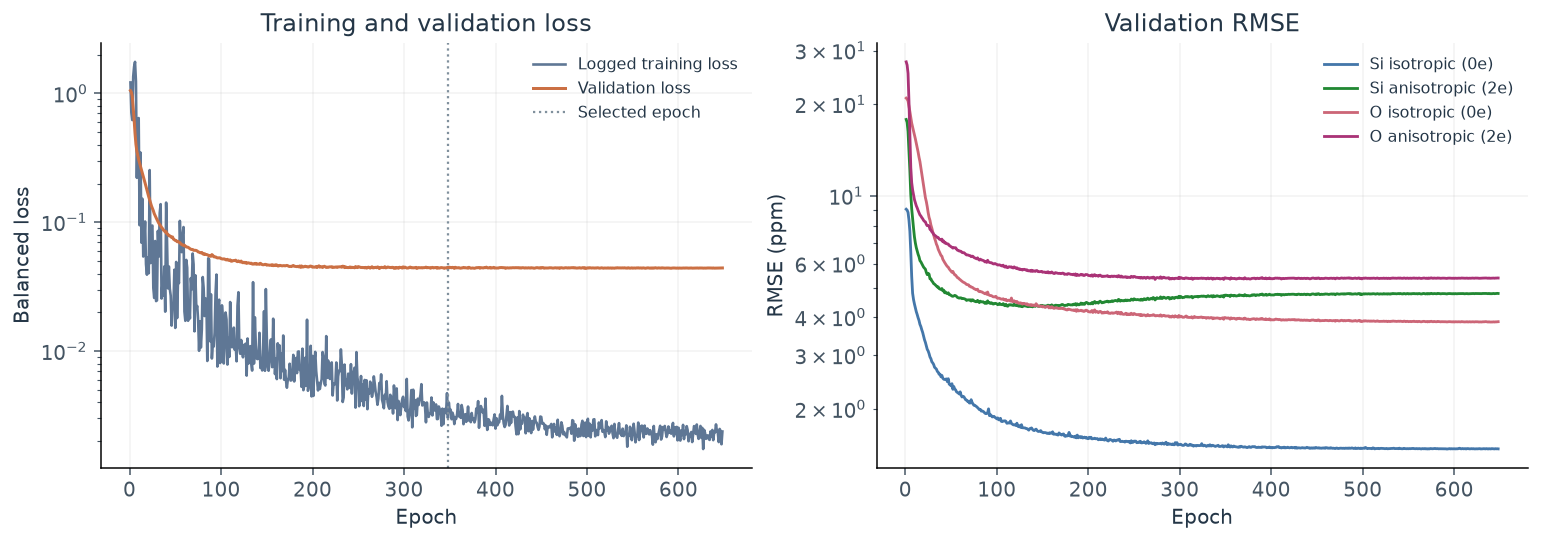

findfont: Failed to find font weight medium for DejaVu Sans, now using 400.


In [3]:
fig = plot_run_history(DATA, LABEL)
save_figure(fig, FIGURES, 'training-progress')
plt.show()


## Soprano NMR parameter evaluation

Primary parity plots now compare isotropic shielding σiso, Haeberlen anisotropy Δσ and asymmetry η, using Soprano MSIsotropy/MSAnisotropy/MSAsymmetry on original DFT ms tensors and reconstructed predictions. Isotropy and anisotropy are in ppm; asymmetry is dimensionless. Tiny circles retain all atoms. Red points mark opposite anisotropy signs, including possible principal-axis ordering crossings; all remain in the metrics. The model, original tensor loss and validation-selected checkpoint are unchanged.

[Three-method Soprano report](SymmetricTensor-N100-Soprano-Parameters.ipynb) includes the sign-ordering diagnostics.

In [4]:
from analysis_helpers.nmr_parameters import prepare_parameters, load_parameter_metrics, plot_run_parameter_parity, PARAMETERS
PARAMETER_DATA = ROOT / 'experiments/symmetric-transfer-N100-data/nmr-parameters'
if RECOMPUTE:
    prepare_parameters(ROOT)
parameter_metrics = load_parameter_metrics(ROOT)
comparison = parameter_metrics[parameter_metrics.Experiment.isin(['01', LABEL]) & parameter_metrics.Split.isin(['validation','test']) & parameter_metrics.Parameter.isin(PARAMETERS)]
display(comparison[['Method','Split','Element','Parameter','Units','N','RMSE','MAE','R2']].rename(columns={'R2':'R²'}).reset_index(drop=True))


,Method,Split,Element,Parameter,Units,N,RMSE,MAE,R²
0,Direct training,validation,Si,isotropy,ppm,2400,2.0601,0.8810,0.9483
1,Direct training,validation,Si,anisotropy,ppm,2400,25.7146,8.7898,0.6872
2,Direct training,validation,Si,asymmetry,dimensionless,2400,0.1392,0.0989,0.6618
3,Direct training,validation,O,isotropy,ppm,4800,3.9233,1.9615,0.9649
4,Direct training,validation,O,anisotropy,ppm,4800,23.4487,6.6737,0.5669
5,Direct training,validation,O,asymmetry,dimensionless,4800,0.1117,0.0721,0.7710
6,Full fine-tuning,validation,Si,isotropy,ppm,2400,1.5006,0.6986,0.9726
7,Full fine-tuning,validation,Si,anisotropy,ppm,2400,22.8634,6.9009,0.7527
8,Full fine-tuning,validation,Si,asymmetry,dimensionless,2400,0.1309,0.0908,0.7009
9,Full fine-tuning,validation,O,isotropy,ppm,4800,3.9394,1.7302,0.9646


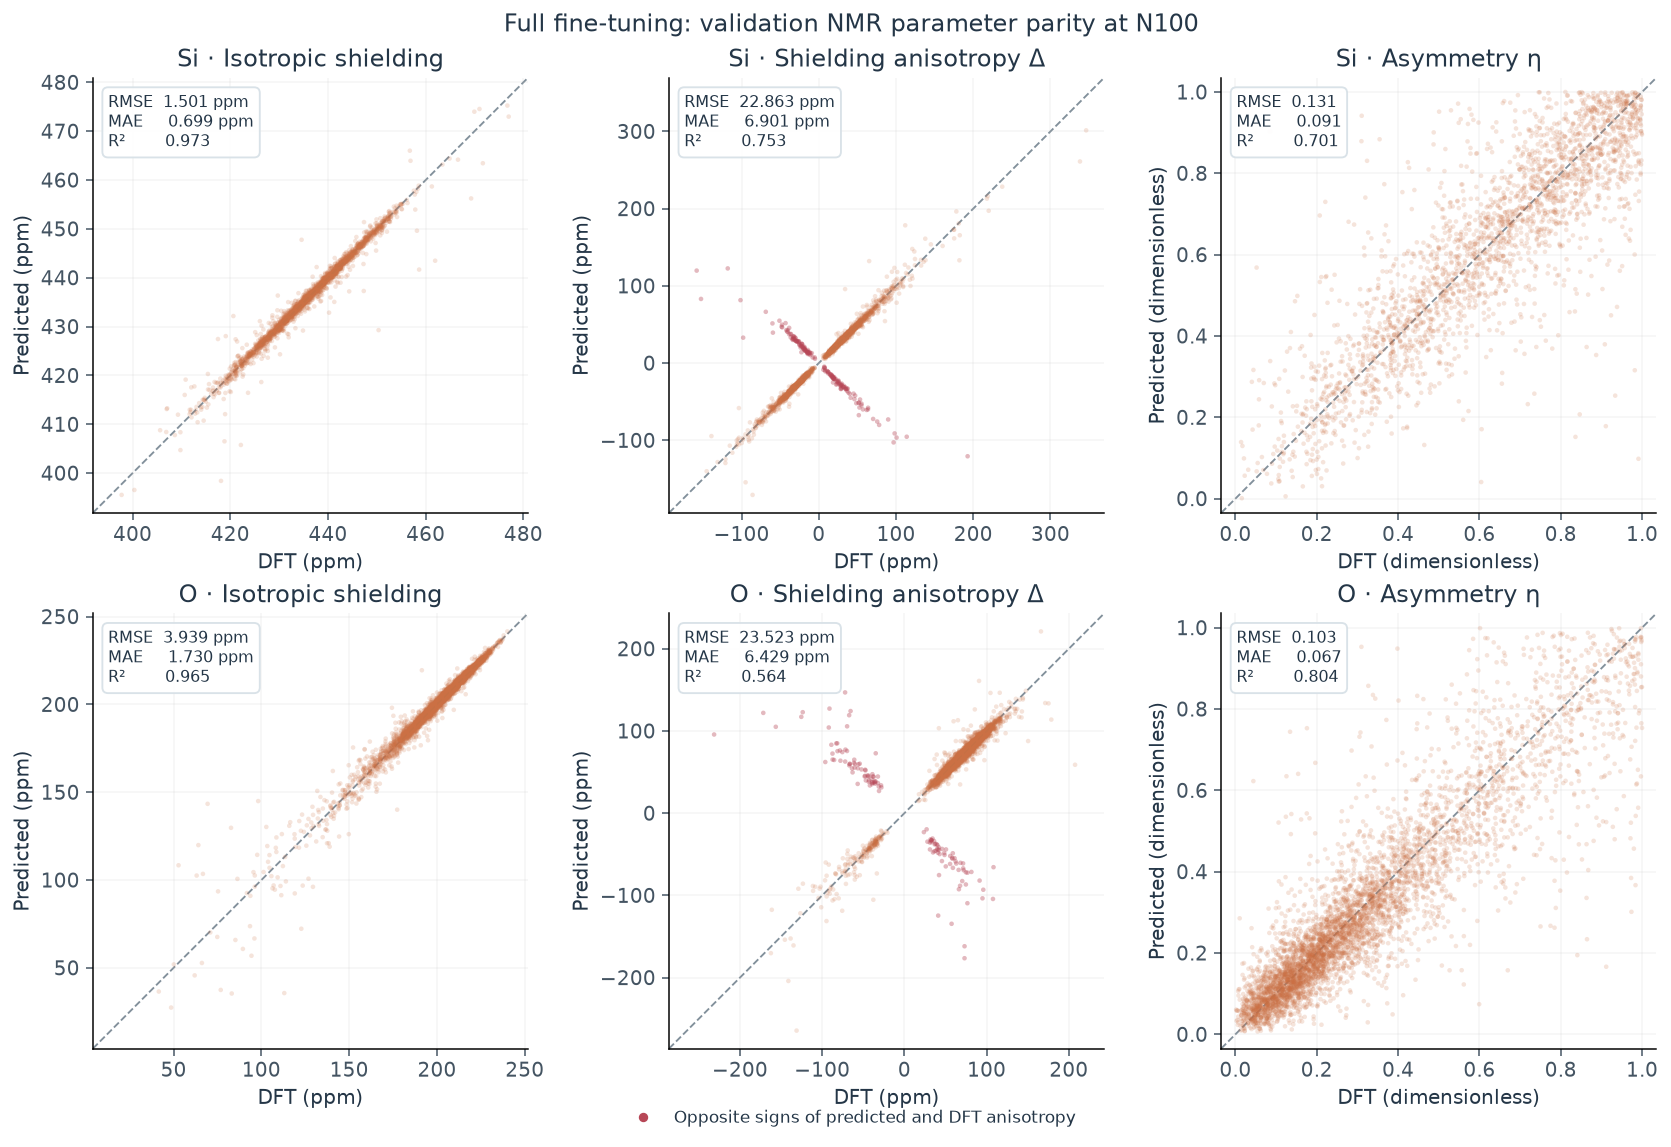

In [5]:
fig = plot_run_parameter_parity(PARAMETER_DATA, LABEL, 'validation')
save_figure(fig, FIGURES, 'validation-nmr-parameters')
plt.show()


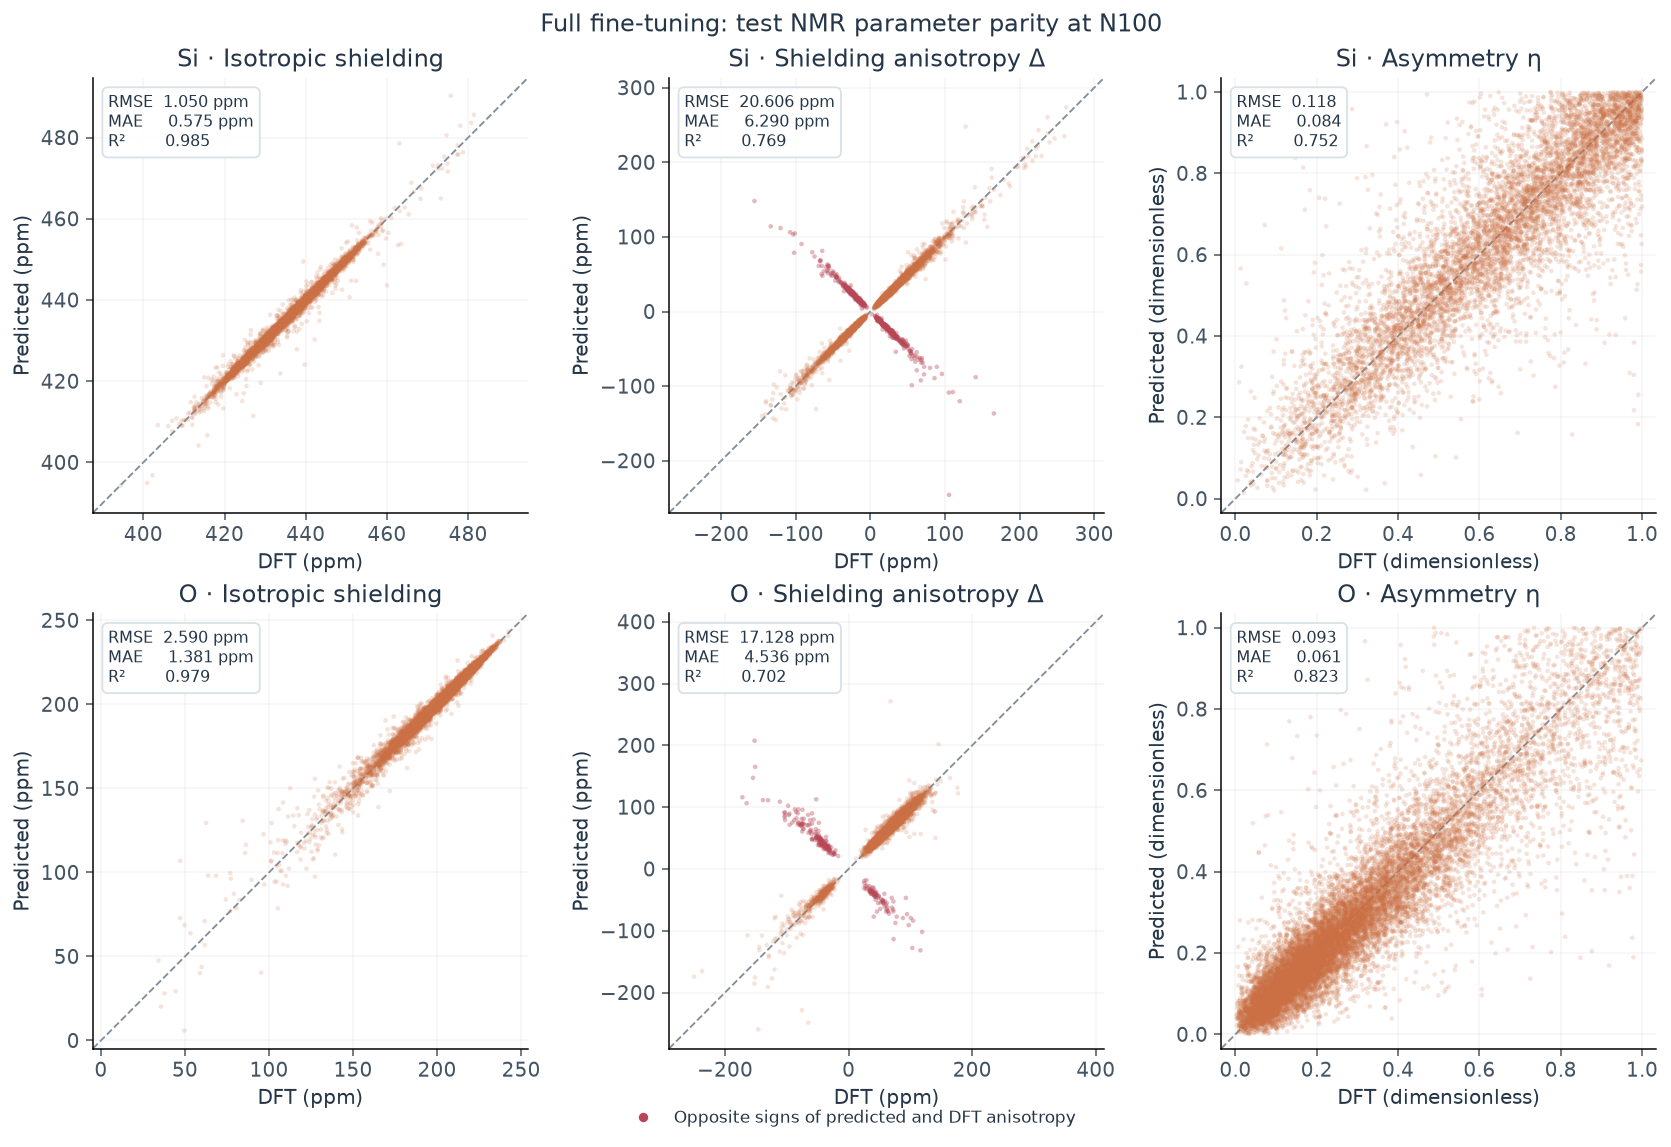

In [6]:
fig = plot_run_parameter_parity(PARAMETER_DATA, LABEL, 'test')
save_figure(fig, FIGURES, 'test-nmr-parameters')
plt.show()


## NMR parameter interpretation

Both transfer recipes improve the six primary test RMSE quantities relative to direct training. ELoRA has lower anisotropy RMSE, while full fine-tuning has lower asymmetry RMSE. Signed anisotropy errors include opposite-sign cases; use the unfiltered scores alongside the ordering diagnostic in the Soprano report. This parameter evaluation does not replace the original tensor training objective or test tensor accuracy.

## Original tensor-score interpretation

Full fine-tuning does not improve all four outputs. The combined validation loss is slightly worse than direct training; isotropic and anisotropic results must be interpreted separately. This is one preset learning rate and one seed, so it does not establish that full fine-tuning or E/F pretraining is generally ineffective.

Test RMSE: Si isotropic **1.050 ppm**, Si anisotropic **3.042 ppm**; O isotropic **2.590 ppm**, O anisotropic **3.971 ppm**.

See [the direct training / full fine-tuning / ELoRA comparison](SymmetricTensor-N100-Transfer-Comparison.ipynb) for all three methods, the `2e` comparison and validation feature-change diagnostics. These single-seed results support conclusions about these recipes and this stored split.

The previous tensor-component parity exports remain available as `validation-parity.png` and `test-parity.png` alongside this notebook.

## Component-resolved anisotropic analysis

[The anisotropic component notebook](SymmetricTensor-N100-Anisotropic-Components.ipynb) compares all five coefficient RMSEs, Cartesian tensor-entry errors and the influence of rare large errors for direct training, full fine-tuning and ELoRA.